# EC class prediction from ESM-2 embeddings

Pipeline: **FASTA → QC → ESM-2 embedding (mean-pooled) → classifier → EC class (1–7)**.

1. Setup
2. Data: cached embeddings (from `clustering.ipynb`) and the two train/test splits (Random, MaxMin)
3. Baseline: one-vs-rest logistic regression
4. Tree ensembles with grid search (cached: delete `outputs/tree_models.joblib` to re-run, ~35 min on 16 cores)
5. Best model: confusion matrices
6. End-to-end demo: 100 random enzymes not used anywhere above → embed → predict → evaluate

## 1. Setup

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
)

SEED = 42
OUTPUT_DIR = Path('outputs')
FASTA_DIR = Path('../../datasets/original') if Path('../../datasets/original').is_dir() else Path('data')

# Must match clustering.ipynb, otherwise new embeddings are not comparable
MODEL_NAME = 'facebook/esm2_t6_8M_UR50D'
MAX_RESIDUES = 1022
BATCH_SIZE = 4

sns.set_theme(style='white', context='notebook')

In [2]:
def plot_confusion(ax, y_true, y_pred, classes, title, cbar=True):
    """Multiclass confusion matrix: colour = row-normalised recall, text = count + %."""
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    row_pct = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    annot = np.array([[f'{cm[r, c]}\n{row_pct[r, c]:.0%}' for c in range(len(classes))]
                      for r in range(len(classes))])
    sns.heatmap(row_pct, annot=annot, fmt='', cmap='Blues', vmin=0, vmax=1,
                square=True, linewidths=1, linecolor='white', cbar=cbar,
                xticklabels=[f'EC {c}' for c in classes],
                yticklabels=[f'EC {c}' for c in classes],
                cbar_kws={'label': 'Row-normalised', 'shrink': 0.8} if cbar else None, ax=ax)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    return cm

## 2. Data: embeddings and splits

Embeddings come from `clustering.ipynb` (ESM-2 8M, mean-pooled over residues, 7 EC classes × 1000). Row order matches `sample_clusters.csv`.
Both splits are 80/20: **Random** (stratified by EC) and **MaxMin** (test = the most mutually distant proteins, chosen on PCA-50 + L2-normalised embeddings).

In [3]:
X = np.load(OUTPUT_DIR / 'esm2_embeddings_927071f4384be30d.npz')['X']
meta = pd.read_csv(OUTPUT_DIR / 'sample_clusters.csv')
y = meta['ec_class'].to_numpy()
Xn = normalize(X)  # L2-normalised, as in clustering.ipynb; all models use Xn
classes = np.unique(y)

assert len(X) == len(meta)
print('X:', X.shape, '| classes:', dict(zip(*np.unique(y, return_counts=True))))

X: (7000, 320) | classes: {np.int64(1): np.int64(1000), np.int64(2): np.int64(1000), np.int64(3): np.int64(1000), np.int64(4): np.int64(1000), np.int64(5): np.int64(1000), np.int64(6): np.int64(1000), np.int64(7): np.int64(1000)}


In [4]:
npz = np.load(OUTPUT_DIR / 'maxmin_vs_random_splits.npz')
splits = {
    'MaxMin': (npz['maxmin_train_idx'], npz['maxmin_test_idx']),
    'Random': (npz['random_train_idx'], npz['random_test_idx']),
}

for method, (train_idx, test_idx) in splits.items():
    assert len(np.intersect1d(train_idx, test_idx)) == 0
    assert len(train_idx) + len(test_idx) == len(X)
    print(f'{method:>6}: train={len(train_idx)}, test={len(test_idx)}')

# Class distribution of each test set
pd.DataFrame({m: pd.Series(y[te]).value_counts().sort_index() for m, (_, te) in splits.items()}).rename_axis('EC class')

MaxMin: train=5600, test=1400
Random: train=5600, test=1400


,MaxMin,Random
EC class,,
1,236,200
2,302,200
3,326,200
4,179,200
5,163,200
6,96,200
7,98,200


## 3. Baseline: one-vs-rest logistic regression

One binary model per EC class; the multiclass prediction is the argmax of the 7 OvR probabilities.

In [5]:
from sklearn.linear_model import LogisticRegression

models = {}
lr_results = []

for method, (tr, te) in splits.items():

    X_train, X_test = Xn[tr], Xn[te]

    for ec in np.unique(y):

        y_train = (y[tr] == ec).astype(int)
        y_test = (y[te] == ec).astype(int)

        model = LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=SEED
        )

        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        models[(method, ec)] = model

        lr_results.append({
            "Method": method,
            "EC": ec,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1": f1_score(y_test, y_pred, zero_division=0),
            "ROC AUC": roc_auc_score(y_test, y_prob)
        })

lr_results = pd.DataFrame(lr_results)

display(lr_results.round(4))

,Method,EC,Accuracy,Precision,Recall,F1,ROC AUC
0,MaxMin,1,0.7707,0.4000,0.7203,0.5144,0.8350
1,MaxMin,2,0.7286,0.4211,0.6887,0.5226,0.7967
2,MaxMin,3,0.7521,0.4819,0.8558,0.6166,0.8493
3,MaxMin,4,0.7614,0.3018,0.6592,0.4140,0.7927
4,MaxMin,5,0.7493,0.2565,0.6074,0.3607,0.7667
5,MaxMin,6,0.8579,0.3012,0.8125,0.4394,0.9212
6,MaxMin,7,0.9007,0.3829,0.6837,0.4908,0.9027
7,Random,1,0.8379,0.4569,0.7150,0.5575,0.8884
8,Random,2,0.8093,0.3976,0.6500,0.4934,0.8311
9,Random,3,0.8443,0.4740,0.8200,0.6007,0.9060


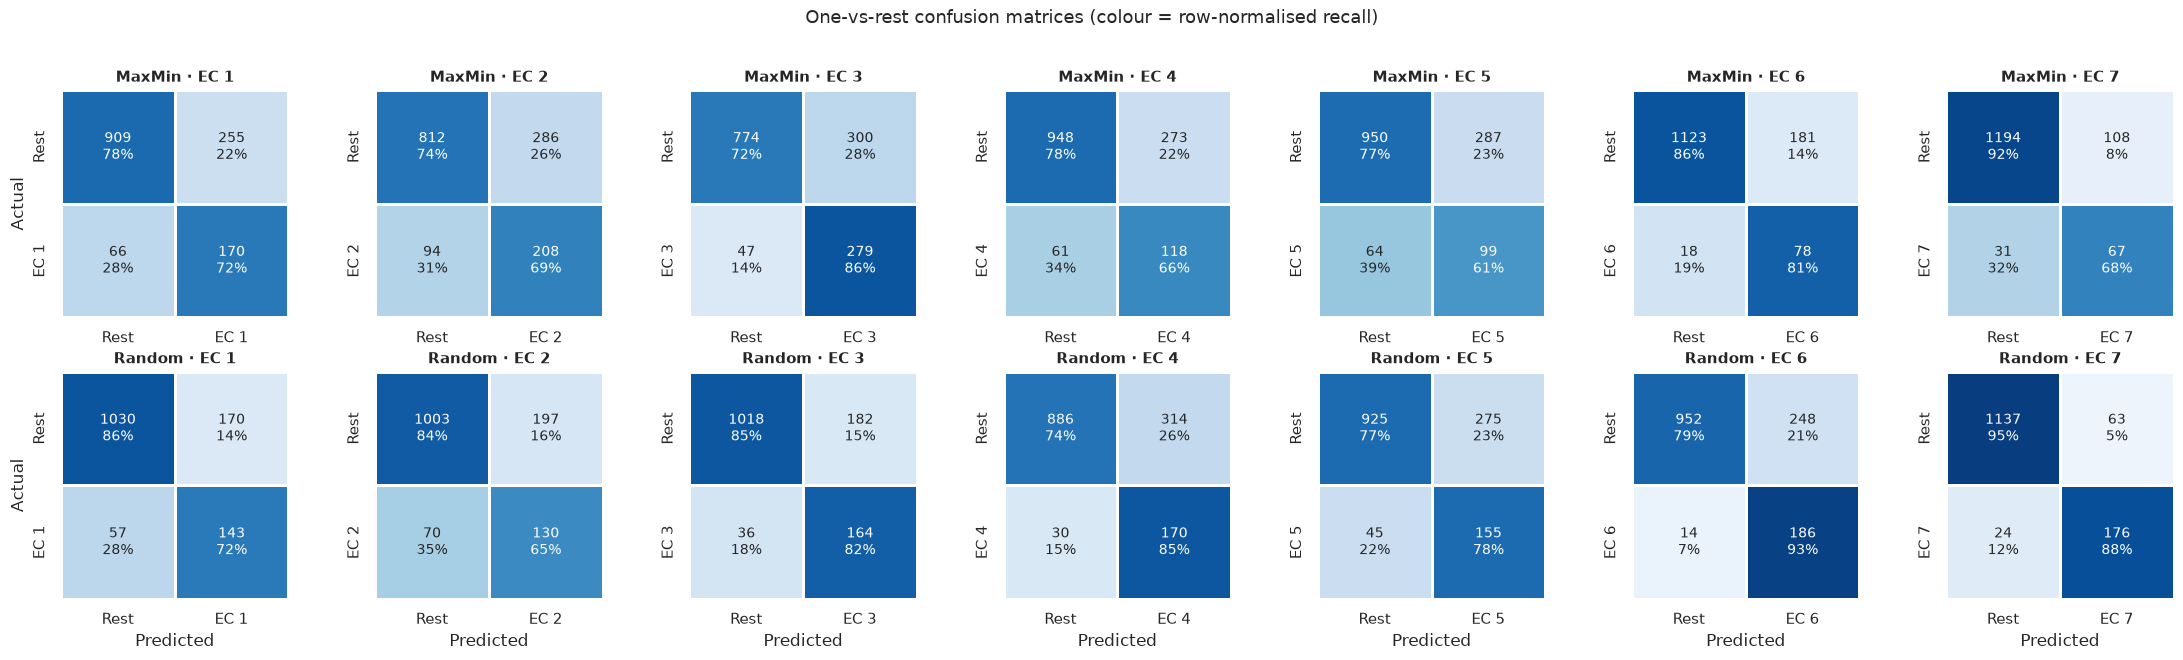

In [6]:
methods = list(splits.keys())

# ---------- 1. Binary one-vs-rest matrices: rows = split, cols = EC ----------
fig, axes = plt.subplots(
    len(methods), len(classes),
    figsize=(3.2 * len(classes), 3.2 * len(methods)),
    squeeze=False
)

for i, (method, (tr, te)) in enumerate(splits.items()):
    X_test, y_true = Xn[te], y[te]
    for j, ec in enumerate(classes):
        yt = (y_true == ec).astype(int)
        yp = models[(method, ec)].predict(X_test)
        cm = confusion_matrix(yt, yp, labels=[0, 1])

        # annotation: count + row percentage
        row_pct = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
        annot = np.array([[f"{cm[r, c]}\n{row_pct[r, c]:.0%}" for c in range(2)]
                          for r in range(2)])

        ax = axes[i, j]
        sns.heatmap(
            row_pct, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1,
            cbar=False, square=True, linewidths=1, linecolor="white",
            xticklabels=["Rest", f"EC {ec}"], yticklabels=["Rest", f"EC {ec}"],
            annot_kws={"fontsize": 10}, ax=ax
        )
        ax.set_title(f"{method} · EC {ec}", fontsize=11, fontweight="bold")
        ax.set_xlabel("Predicted" if i == len(methods) - 1 else "")
        ax.set_ylabel("Actual" if j == 0 else "")

fig.suptitle("One-vs-rest confusion matrices (colour = row-normalised recall)",
             fontsize=13, y=1.02)
fig.tight_layout()
plt.show()

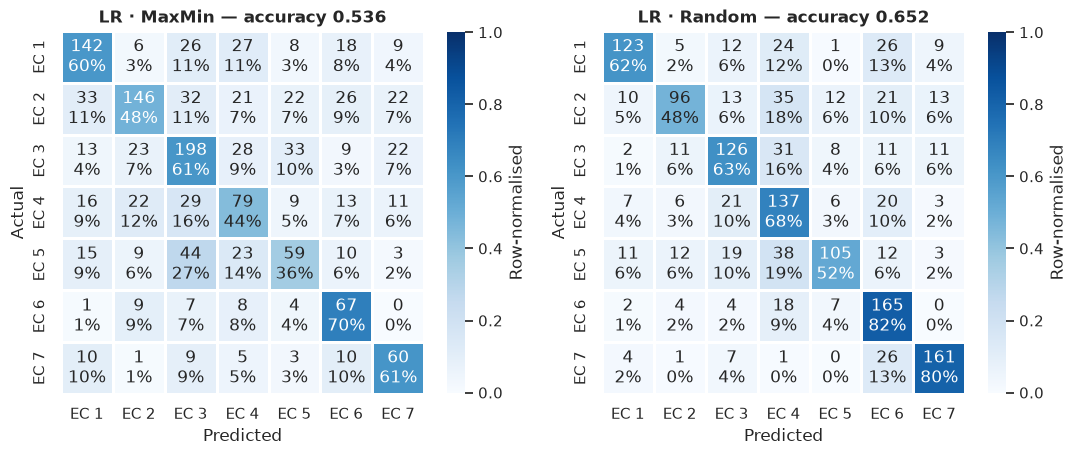

In [7]:
# Multiclass matrices (argmax of OvR probabilities)
fig, axes = plt.subplots(1, len(splits), figsize=(5.5 * len(splits), 5), squeeze=False)
for k, (method, (tr, te)) in enumerate(splits.items()):
    probs = np.column_stack([models[(method, ec)].predict_proba(Xn[te])[:, 1] for ec in classes])
    y_pred = classes[probs.argmax(axis=1)]
    plot_confusion(axes[0, k], y[te], y_pred, classes,
                   f'LR · {method} — accuracy {accuracy_score(y[te], y_pred):.3f}')
fig.tight_layout()
plt.show()

## 4. Tree ensembles with grid search

Hyperparameters are tuned with 5-fold CV on the **train part** of each split only; the test part is used once.
The run takes ~35 min, so models and tables are cached in `outputs/`. Delete `outputs/tree_models.joblib` to recompute.

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

model_specs = {
    'DecisionTree': (
        DecisionTreeClassifier(class_weight='balanced', random_state=SEED),
        {
            'max_depth': [5, 10, 20, None],
            'min_samples_leaf': [1, 5, 10],
            'max_features': [None, 'sqrt'],   # sqrt(320) ≈ 18 features per split
            'ccp_alpha': [0.0, 1e-3, 1e-2],   # cost-complexity pruning
        },
    ),
    'RandomForest': (
        RandomForestClassifier(n_estimators=500, class_weight='balanced_subsample',
                               n_jobs=-1, random_state=SEED),
        {'max_depth': [None, 20], 'min_samples_leaf': [1, 3], 'max_features': ['sqrt', 0.1]},
    ),
    'ExtraTrees': (
        ExtraTreesClassifier(n_estimators=500, class_weight='balanced',
                             n_jobs=-1, random_state=SEED),
        {'max_depth': [None, 20], 'min_samples_leaf': [1, 3], 'max_features': ['sqrt', 0.1]},
    ),
    'HistGradBoost': (
        HistGradientBoostingClassifier(class_weight='balanced', early_stopping=True,
                                       random_state=SEED),
        {'learning_rate': [0.05, 0.1], 'max_leaf_nodes': [15, 31], 'l2_regularization': [0.0, 1.0]},
    ),
}

In [9]:
def run_grid_search():
    tree_models, tree_results, tree_summary = {}, [], []
    for method, (tr, te) in splits.items():
        X_train, X_test = Xn[tr], Xn[te]
        y_train, y_test = y[tr], y[te]

        for name, (estimator, grid) in model_specs.items():
            search = GridSearchCV(estimator, grid, scoring='f1_macro', cv=cv, n_jobs=-1, refit=True)
            search.fit(X_train, y_train)
            model = search.best_estimator_
            tree_models[(method, name)] = model

            y_pred = model.predict(X_test)
            proba = model.predict_proba(X_test)
            col = {c: i for i, c in enumerate(model.classes_)}

            tree_summary.append({
                'Method': method, 'Model': name,
                'Accuracy': accuracy_score(y_test, y_pred),
                'Balanced Acc': balanced_accuracy_score(y_test, y_pred),
                'Macro F1': f1_score(y_test, y_pred, average='macro', zero_division=0),
                'Weighted F1': f1_score(y_test, y_pred, average='weighted', zero_division=0),
                'CV Macro F1': search.best_score_,
                'Best params': search.best_params_,
            })

            # Per-EC one-vs-rest metrics (comparable to the LR table)
            for ec in classes:
                yt = (y_test == ec).astype(int)
                yp = (y_pred == ec).astype(int)
                p = proba[:, col[ec]] if ec in col else np.zeros(len(yt))
                tree_results.append({
                    'Method': method, 'Model': name, 'EC': ec,
                    'Accuracy': accuracy_score(yt, yp),
                    'Precision': precision_score(yt, yp, zero_division=0),
                    'Recall': recall_score(yt, yp, zero_division=0),
                    'F1': f1_score(yt, yp, zero_division=0),
                    'ROC AUC': roc_auc_score(yt, p) if yt.min() != yt.max() else np.nan,
                })

            print(f'[{method:6}] {name:14} test macro-F1 = '
                  f"{tree_summary[-1]['Macro F1']:.4f}  best = {search.best_params_}", flush=True)

    return tree_models, pd.DataFrame(tree_results), pd.DataFrame(tree_summary)


cache = OUTPUT_DIR / 'tree_models.joblib'
if cache.exists():
    tree_models = joblib.load(cache)
    tree_results = pd.read_csv(OUTPUT_DIR / 'tree_results.csv')
    tree_summary = pd.read_csv(OUTPUT_DIR / 'tree_summary.csv')
    print('Loaded cached grid-search results:', sorted(tree_models))
else:
    tree_models, tree_results, tree_summary = run_grid_search()
    joblib.dump(tree_models, cache, compress=3)
    tree_results.to_csv(OUTPUT_DIR / 'tree_results.csv', index=False)
    tree_summary.to_csv(OUTPUT_DIR / 'tree_summary.csv', index=False)

Loaded cached grid-search results: [('MaxMin', 'DecisionTree'), ('MaxMin', 'ExtraTrees'), ('MaxMin', 'HistGradBoost'), ('MaxMin', 'RandomForest'), ('Random', 'DecisionTree'), ('Random', 'ExtraTrees'), ('Random', 'HistGradBoost'), ('Random', 'RandomForest')]


In [10]:
display(tree_summary.drop(columns='Best params').round(4))
display(tree_summary.pivot(index='Model', columns='Method', values='Macro F1').round(4))
display(tree_results.round(4))

,Method,Model,Accuracy,Balanced Acc,Macro F1,Weighted F1,CV Macro F1
0,MaxMin,DecisionTree,0.4321,0.4402,0.4302,0.4332,0.5963
1,MaxMin,RandomForest,0.7150,0.7129,0.7108,0.7149,0.7995
2,MaxMin,ExtraTrees,0.7386,0.7387,0.7353,0.7388,0.8142
3,MaxMin,HistGradBoost,0.7086,0.7067,0.7149,0.7095,0.8043
4,Random,DecisionTree,0.5664,0.5664,0.5654,0.5654,0.5485
5,Random,RandomForest,0.8171,0.8171,0.8184,0.8184,0.7876
6,Random,ExtraTrees,0.8264,0.8264,0.8277,0.8277,0.7992
7,Random,HistGradBoost,0.8157,0.8157,0.8170,0.8170,0.7895


Method,MaxMin,Random
Model,,
DecisionTree,0.4302,0.5654
ExtraTrees,0.7353,0.8277
HistGradBoost,0.7149,0.8170
RandomForest,0.7108,0.8184


,Method,Model,EC,Accuracy,Precision,Recall,F1,ROC AUC
0,MaxMin,DecisionTree,1,0.8093,0.4286,0.3941,0.4106,0.6397
1,MaxMin,DecisionTree,2,0.7507,0.4164,0.3874,0.4014,0.6240
2,MaxMin,DecisionTree,3,0.7900,0.5537,0.5061,0.5288,0.6932
3,MaxMin,DecisionTree,4,0.8386,0.3642,0.3520,0.3580,0.6423
4,MaxMin,DecisionTree,5,0.8371,0.3367,0.4110,0.3702,0.6528
5,MaxMin,DecisionTree,6,0.9100,0.3828,0.5104,0.4375,0.7343
6,MaxMin,DecisionTree,7,0.9286,0.4904,0.5204,0.5050,0.7373
7,MaxMin,RandomForest,1,0.9064,0.7333,0.6992,0.7158,0.9172
8,MaxMin,RandomForest,2,0.8893,0.7795,0.6788,0.7257,0.8900
9,MaxMin,RandomForest,3,0.8857,0.7243,0.8221,0.7701,0.9381


In [11]:
for method in splits:
    rf = tree_models[(method, 'RandomForest')]
    imp = pd.Series(rf.feature_importances_, name='importance')
    print(f'\n{method} — RandomForest top 20 features')
    print(imp.sort_values(ascending=False).head(20).round(4).to_string())


MaxMin — RandomForest top 20 features
308    0.0090
1      0.0084
89     0.0082
7      0.0067
248    0.0067
303    0.0066
311    0.0065
58     0.0064
202    0.0063
235    0.0059
41     0.0058
34     0.0057
106    0.0056
38     0.0056
154    0.0056
306    0.0055
118    0.0054
79     0.0053
157    0.0053
44     0.0053

Random — RandomForest top 20 features
1      0.0111
308    0.0103
89     0.0093
202    0.0083
58     0.0081
303    0.0076
235    0.0075
248    0.0075
311    0.0074
7      0.0074
104    0.0070
44     0.0062
118    0.0061
281    0.0061
15     0.0060
106    0.0059
38     0.0057
154    0.0056
307    0.0056
289    0.0055


## 5. Best model

The best model is chosen by **test macro-F1 on the MaxMin split**, the harder and more realistic setting (test proteins far from the training set).
CV scores are not compared across splits: they are computed inside different training pools.

Best model: ExtraTrees


,Method,Model,Accuracy,Balanced Acc,Macro F1,Weighted F1,CV Macro F1
2,MaxMin,ExtraTrees,0.7386,0.7387,0.7353,0.7388,0.8142
6,Random,ExtraTrees,0.8264,0.8264,0.8277,0.8277,0.7992


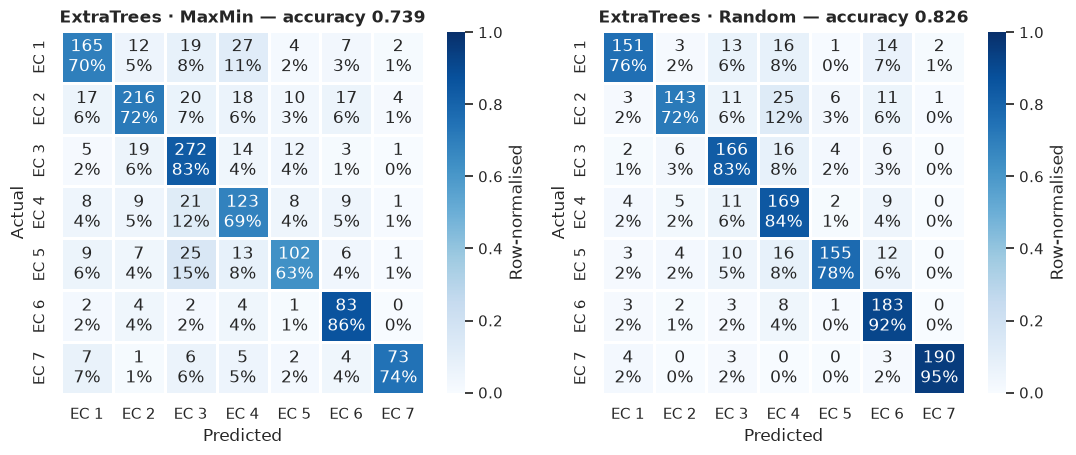

In [17]:
best_name = (tree_summary.query("Method == 'MaxMin'")
             .sort_values('Macro F1', ascending=False)['Model'].iloc[0])
print('Best model:', best_name)
display(tree_summary.query('Model == @best_name').drop(columns='Best params').round(4))

fig, axes = plt.subplots(1, len(splits), figsize=(5.5 * len(splits), 5), squeeze=False)
for k, (method, (tr, te)) in enumerate(splits.items()):
    y_pred = tree_models[(method, best_name)].predict(Xn[te])
    plot_confusion(axes[0, k], y[te], y_pred, classes,
                   f'{best_name} · {method} — accuracy {accuracy_score(y[te], y_pred):.3f}')
fig.tight_layout()
plt.savefig(OUTPUT_DIR / f'confusion_{best_name}.png', dpi=160, bbox_inches='tight')
plt.show()

## 6. End-to-end pipeline on new enzymes

1. Read all UniProt FASTA files (EC class = number in the file name).
2. Same QC as `clustering.ipynb`: allowed letters, length ≤ 1022, drop sequences listed under several EC classes, drop duplicates.
3. Exclude every protein used above (all 7000 by ID and by sequence), then draw **100 at random** (natural EC frequencies, not balanced).
4. Embed with the same ESM-2 model and pooling.
5. Score **both** ExtraTrees models from section 4 exactly as trained (one on the MaxMin train part, one on the Random train part, no refit) on the **same** 100 enzymes.
   The 100 enzymes are outside both training sets, so the held-out data are identical for both models; only the training data differ.

Excluding identical sequences does not exclude close homologs, so this estimate sits closer to the Random split than to MaxMin.

In [18]:
from Bio import SeqIO

records = []
for path in sorted(FASTA_DIR.glob('uniprotkb_ec_*_AND_reviewed_true_*.fasta')):
    ec_class = int(re.search(r'uniprotkb_ec_([1-7])_AND_', path.name).group(1))
    for rec in SeqIO.parse(path, 'fasta'):
        seq = str(rec.seq).upper().replace(' ', '')
        records.append({'id': rec.id, 'sequence': seq, 'ec_class': ec_class})
pool = pd.DataFrame(records)
print('All records:', len(pool))

# QC identical to clustering.ipynb
allowed = set('ACDEFGHIKLMNPQRSTVWYUBZOX')
pool = pool[pool['sequence'].map(lambda s: bool(s) and len(s) <= MAX_RESIDUES and set(s) <= allowed)]
n_ec = pool.groupby('sequence')['ec_class'].nunique()
pool = pool[~pool['sequence'].isin(n_ec[n_ec > 1].index)].drop_duplicates(subset=['sequence'])

# Exclude everything the models have seen (train or test)
pool = pool[~pool['id'].isin(meta['id']) & ~pool['sequence'].isin(meta['sequence'])]
print('Eligible unseen enzymes:', len(pool))

new = pool.sample(n=100, random_state=SEED).reset_index(drop=True)
new['model_sequence'] = new['sequence'].str.replace(r'[UBZO]', 'X', regex=True)
display(new['ec_class'].value_counts().sort_index().rename_axis('EC class').to_frame('n'))

All records: 288097
Eligible unseen enzymes: 216794


,n
EC class,
1,11
2,39
3,21
4,11
5,6
6,8
7,4


In [19]:
import torch
from transformers import AutoTokenizer, AutoModel

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
esm = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE).eval()


def embed(seqs, batch_size=BATCH_SIZE):
    """Mean-pooled ESM-2 embedding over residues (no BOS/EOS/padding), as in clustering.ipynb."""
    vectors = []
    for start in range(0, len(seqs), batch_size):
        chunk = seqs[start:start + batch_size]
        batch = tokenizer(chunk, padding=True, return_tensors='pt', add_special_tokens=True)
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with torch.inference_mode():
            hidden = esm(**batch).last_hidden_state
        for j, seq in enumerate(chunk):
            vectors.append(hidden[j, 1:1 + len(seq)].mean(dim=0).float().cpu().numpy())
    return np.stack(vectors).astype(np.float32)


# Sanity check: re-embedding a few training proteins must reproduce the cached vectors
check_idx = [0, 1, 2, 3]
check_seqs = meta.loc[check_idx, 'sequence'].str.replace(r'[UBZO]', 'X', regex=True).tolist()
diff = np.abs(embed(check_seqs) - X[check_idx]).max()
print(f'Device: {DEVICE} | max |Δ| vs cached embeddings: {diff:.2e}')
assert diff < 1e-3, 'Embedding pipeline differs from clustering.ipynb'

X_new = embed(new['model_sequence'].tolist())
Xn_new = normalize(X_new)
print('New embeddings:', X_new.shape)

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t6_8M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Device: cuda | max |Δ| vs cached embeddings: 2.86e-06
New embeddings: (100, 320)


In [20]:
# Both ExtraTrees models exactly as trained in section 4 (each on its own 5600-protein train part)
split_models = {m: tree_models[(m, best_name)] for m in splits}

# Held-out check: no new enzyme is in either training set (by ID or by sequence),
# and both models are scored on the very same rows
new_ids, new_seqs = set(new['id']), set(new['sequence'])
for m, (tr, _) in splits.items():
    assert not new_ids & set(meta.loc[tr, 'id']), f'ID overlap with {m} train'
    assert not new_seqs & set(meta.loc[tr, 'sequence']), f'sequence overlap with {m} train'
assert len(new) == len(Xn_new) == new['id'].nunique() == 100
print('Held-out set: 100 enzymes, identical for both models, none in either training set')

y_new = new['ec_class'].to_numpy()
rows = []
for m, model in split_models.items():
    new[f'pred_{m}'] = model.predict(Xn_new)
    new[f'conf_{m}'] = model.predict_proba(Xn_new).max(axis=1)
    p = new[f'pred_{m}'].to_numpy()
    rows.append({
        'Model': f'{best_name} ({m} train)',
        'Accuracy': accuracy_score(y_new, p),
        'Balanced Acc': balanced_accuracy_score(y_new, p),
        'Macro F1': f1_score(y_new, p, average='macro', zero_division=0),
    })
display(pd.DataFrame(rows).set_index('Model').round(3))
print(f"Models agree on {(new['pred_MaxMin'] == new['pred_Random']).mean():.0%} of the enzymes\n")

for m in split_models:
    print(f'--- {best_name} trained on {m} train ---')
    print(classification_report(y_new, new[f'pred_{m}'], labels=classes,
                                target_names=[f'EC {c}' for c in classes], zero_division=0))

Held-out set: 100 enzymes, identical for both models, none in either training set


,Accuracy,Balanced Acc,Macro F1
Model,,,
ExtraTrees (MaxMin train),0.80,0.799,0.77
ExtraTrees (Random train),0.84,0.839,0.81


Models agree on 90% of the enzymes

--- ExtraTrees trained on MaxMin train ---
              precision    recall  f1-score   support

        EC 1       0.83      0.91      0.87        11
        EC 2       0.91      0.82      0.86        39
        EC 3       0.88      0.71      0.79        21
        EC 4       0.60      0.82      0.69        11
        EC 5       0.67      0.33      0.44         6
        EC 6       0.57      1.00      0.73         8
        EC 7       1.00      1.00      1.00         4

    accuracy                           0.80       100
   macro avg       0.78      0.80      0.77       100
weighted avg       0.83      0.80      0.80       100

--- ExtraTrees trained on Random train ---
              precision    recall  f1-score   support

        EC 1       0.92      1.00      0.96        11
        EC 2       0.94      0.82      0.88        39
        EC 3       0.89      0.81      0.85        21
        EC 4       0.62      0.91      0.74        11
        EC

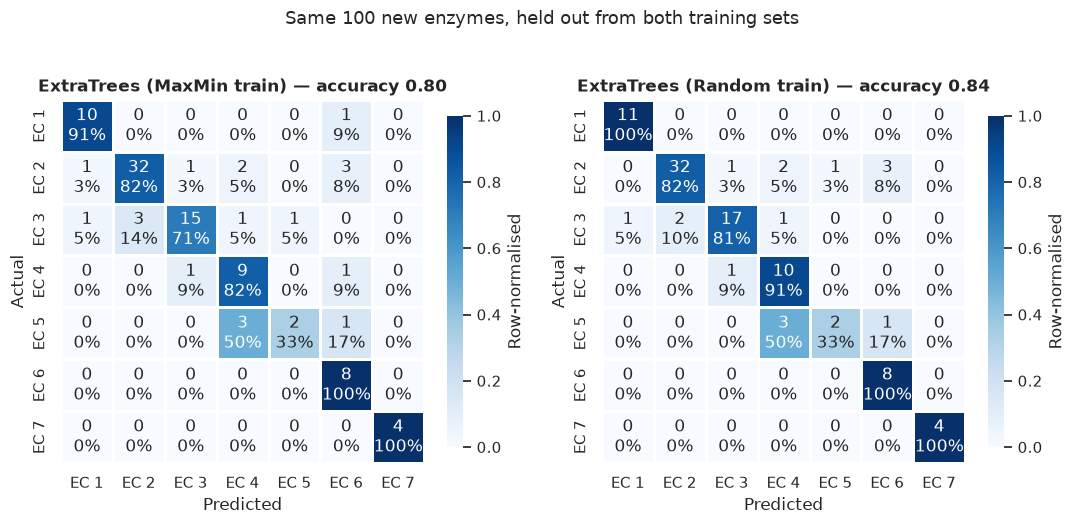

count   mean    std    min    25%    50%    75%    max
       correct                                                        
MaxMin False     20.0  0.306  0.118  0.176  0.206  0.298  0.342  0.594
       True      80.0  0.566  0.245  0.196  0.344  0.507  0.794  0.986
Random False     16.0  0.332  0.079  0.218  0.297  0.308  0.348  0.482
       True      84.0  0.535  0.227  0.208  0.334  0.476  0.728  0.986

,id,ec_class,pred_MaxMin,conf_MaxMin,pred_Random,conf_Random
0,sp|P46953|3HAO_RAT,1,1,0.362,1,0.306
1,sp|O15297|PPM1D_HUMAN,3,3,0.408,3,0.424
2,sp|Q7VF14|MURE_HELHP,6,6,0.826,6,0.734
3,sp|A8G0S7|UBIE_SHESH,2,2,0.732,2,0.594
4,sp|Q67P77|PNP_SYMTH,2,2,0.390,2,0.324
5,sp|Q0SMP6|CLPP_BORAP,3,3,0.872,3,0.812
6,sp|Q8RCU0|PSTB1_CALS4,7,7,0.878,7,0.856
7,sp|Q2KB42|BETB_RHIEC,1,1,0.954,1,0.918
8,sp|A6QB12|CYSN_SULNB,2,3,0.440,3,0.378
9,sp|Q8EUD3|KAD_MALP2,2,2,0.786,2,0.794


In [21]:
fig, axes = plt.subplots(1, len(split_models), figsize=(5.5 * len(split_models), 5), squeeze=False)
for k, m in enumerate(split_models):
    p = new[f'pred_{m}']
    plot_confusion(axes[0, k], y_new, p, classes,
                   f'{best_name} ({m} train) — accuracy {accuracy_score(y_new, p):.2f}')
fig.suptitle('Same 100 new enzymes, held out from both training sets', fontsize=13, y=1.02)
fig.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_new_enzymes.png', dpi=160, bbox_inches='tight')
plt.show()

# Correct predictions tend to have higher confidence
display(pd.concat({m: new.assign(correct=new['ec_class'] == new[f'pred_{m}'])
                         .groupby('correct')[f'conf_{m}'].describe()
                   for m in split_models}).round(3))

cols = ['id', 'ec_class'] + [f'{k}_{m}' for m in split_models for k in ('pred', 'conf')]
display(new[cols].head(15))
new[cols].to_csv(OUTPUT_DIR / 'new_enzymes_predictions.csv', index=False)